# 03 — Dyadic and non-dyadic fractions

**Goal.** Recreate Figure **06** (fraction behavior) and Figure **09** (odd reciprocal fractions) of the English report, and explain why `0.1` and `1/3` begin to show error much earlier than odd integers.

**Sources.** *artigo_ulp.pdf*, Section 5; *relatorio_ulp.pdf*, Sections 4 and 6; `grafico_x10_fracoes.html`.

In [1]:
from pathlib import Path
import sys, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.patches import Patch
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'ulp_lab.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'ulp_lab.py').exists():
    raise FileNotFoundError('Open Jupyter in the extracted ULP_Jupyter_Reproducibility folder.')
sys.path.insert(0, str(ROOT / 'src'))
from ulp_lab import (evaluate, ulp, v2, floor_log2, theory, possible_results,
                     sample_binade, valid_same_binade_mask, generate_cases, validate_one)
FIG = ROOT / 'figures'; FIG.mkdir(exist_ok=True)
RES = ROOT / 'results'; RES.mkdir(exist_ok=True)
BLUE='#2367A6'; ORANGE='#DD8A29'; GREEN='#2C977F'; RED='#B85751'; PURPLE='#8572AB'
plt.rcParams.update({'font.size':10,'figure.dpi':110,'savefig.dpi':190,
                     'axes.grid':True,'grid.alpha':.20,
                     'axes.spines.top':False,'axes.spines.right':False})
print('Working directory:', ROOT)
print('NumPy:', np.__version__)

Working directory: /mnt/data/ULP_Jupyter_Reproducibility
NumPy: 2.3.5


## Fraction classes refer to the **stored** floating-point value

- **Dyadic:** $c=m/2^j$ with odd $m$; the transition width $L$ is the significant bit length of $m$.
- **Non-dyadic real numbers:** numbers such as mathematical $1/3$ or decimal $0.1$ become finite dyadic approximations when stored in float32/float64. Their stored representations often have almost $p$ nonzero significant bits and therefore much wider noisy regions.

The original paper calls the second group “non-dyadic” to describe the *mathematical intended constants*. In actual memory **every finite binary floating-point number is dyadic**.

In [2]:
values=[(3/4,'3/4'),(5/16,'5/16'),(0.1,'0.1'),(1/3,'1/3'),(math.pi,'pi')]
rows=[]
for c,label in values:
    t=theory(c)
    rows.append({'c':label,'stored binary64':repr(np.float64(c).item()),
                 'nu':t.nu,'floor(log2 c)':t.k,'L':t.L,'x1':t.x1,'x2':t.x2})
df=pd.DataFrame(rows)
display(df)
df.to_csv(RES/'03_fraction_thresholds.csv',index=False)
assert theory(3/4).L==2 and theory(5/16).L==3
assert theory(.1).L==52 and theory(1/3).L==53

,c,stored binary64,nu,floor(log2 c),L,x1,x2
0,3/4,0.75,-2,-1,2,34.296751,39.396621
1,5/16,0.3125,-4,-2,3,29.857056,36.758347
2,0.1,0.1,-55,-4,52,0.870551,32.000000
3,1/3,0.3333333333333333,-54,-2,53,0.933033,36.758347
4,pi,3.141592653589793,-48,1,50,1.414214,45.254834


## Figure 06 — relative error for two dyadic and two stored non-dyadic constants

For the bottom row, the *magnitude* of the relative error is shown on a logarithmic scale. Color distinguishes positive from negative error; zero errors are omitted on log axes.

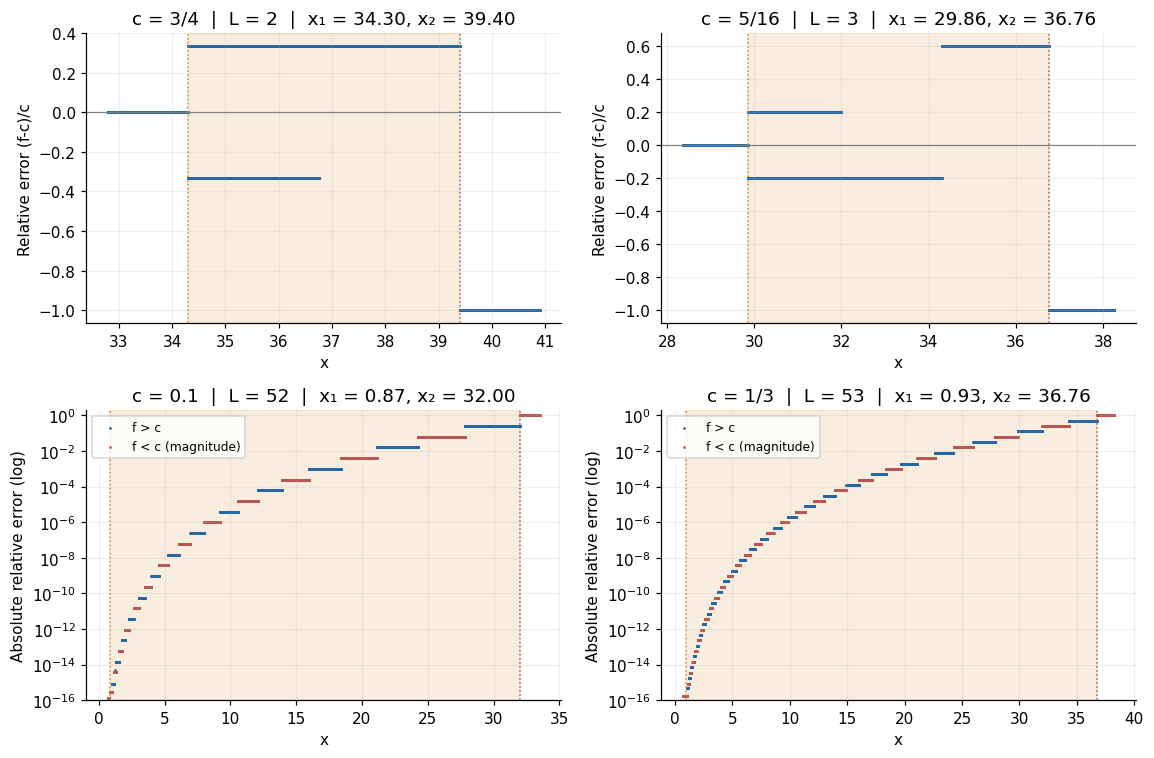

In [3]:
fig,axs=plt.subplots(2,2,figsize=(10.6,7.0))
examples=[(.75,'3/4',False),(5/16,'5/16',False),(.1,'0.1',True),(1/3,'1/3',True)]
for ax,(c,lab,non_dyadic) in zip(axs.ravel(),examples):
    t=theory(c)
    low=max(.3,t.x1*.7) if non_dyadic else t.x1-1.5
    x=np.linspace(low,t.x2+1.5,24000)
    f,_=evaluate(x,c);err=(f-c)/c
    ax.axvspan(t.x1,t.x2,color=ORANGE,alpha=.15)
    ax.axvline(t.x1,color=ORANGE,ls=':',lw=1)
    ax.axvline(t.x2,color=RED,ls=':',lw=1)
    if non_dyadic:
        plus=err>0;minus=err<0
        ax.scatter(x[plus],err[plus],color=BLUE,s=.6,rasterized=True,label='f > c')
        ax.scatter(x[minus],-err[minus],color=RED,s=.6,rasterized=True,label='f < c (magnitude)')
        ax.set_yscale('log');ax.set_ylim(1e-16,2)
        ax.set_ylabel('Absolute relative error (log)')
        ax.legend(fontsize=8,loc='upper left')
    else:
        ax.scatter(x,err,color=BLUE,s=.6,rasterized=True)
        ax.set_ylabel('Relative error (f-c)/c')
        ax.axhline(0,color='gray',lw=.8)
    ax.set(xlabel='x',title=f'c = {lab}  |  L = {t.L}  |  x₁ = {t.x1:.2f}, x₂ = {t.x2:.2f}')
fig.tight_layout()
fig.savefig(FIG / '06_fraction_behaviour.png', bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)

## A numerical table from the paper: relative errors at selected x

These values are evaluated directly, rather than copied from the paper. Tiny differences in the last digits or a sign near zero are possible across NumPy / platform versions.

In [4]:
rows=[]
for x in [1,2,5,10,20,30,32.5]:
    rec={'x':x}
    for c,name in [(.1,'0.1'),(1/3,'1/3')]:
        f,_=evaluate(np.float64(x),c)
        rec[f'rel.err {name}']=float((f-c)/c)
    rows.append(rec)
df=pd.DataFrame(rows)
display(df)
df.to_csv(RES/'03_fraction_relative_errors.csv',index=False)

,x,rel.err 0.1,rel.err 1/3
0,1.0,8.326673e-16,-1.665335e-16
1,2.0,-9.095502e-13,-2.273182e-13
2,5.0,-3.725290e-09,1.862645e-09
3,10.0,3.814697e-06,1.907349e-06
4,20.0,-3.906250e-03,1.953125e-03
5,30.0,2.500000e-01,1.250000e-01
6,32.5,-1.000000e+00,-2.500000e-01


## Figure 09 — reciprocal odd denominators $c=1/d$

This reconstructs the supplied Plotly reciprocal-fraction curves with $d\in\{3,5,9,15\}$. The original HTML can have a different palette or interactive layout; the point values are regenerated numerically.

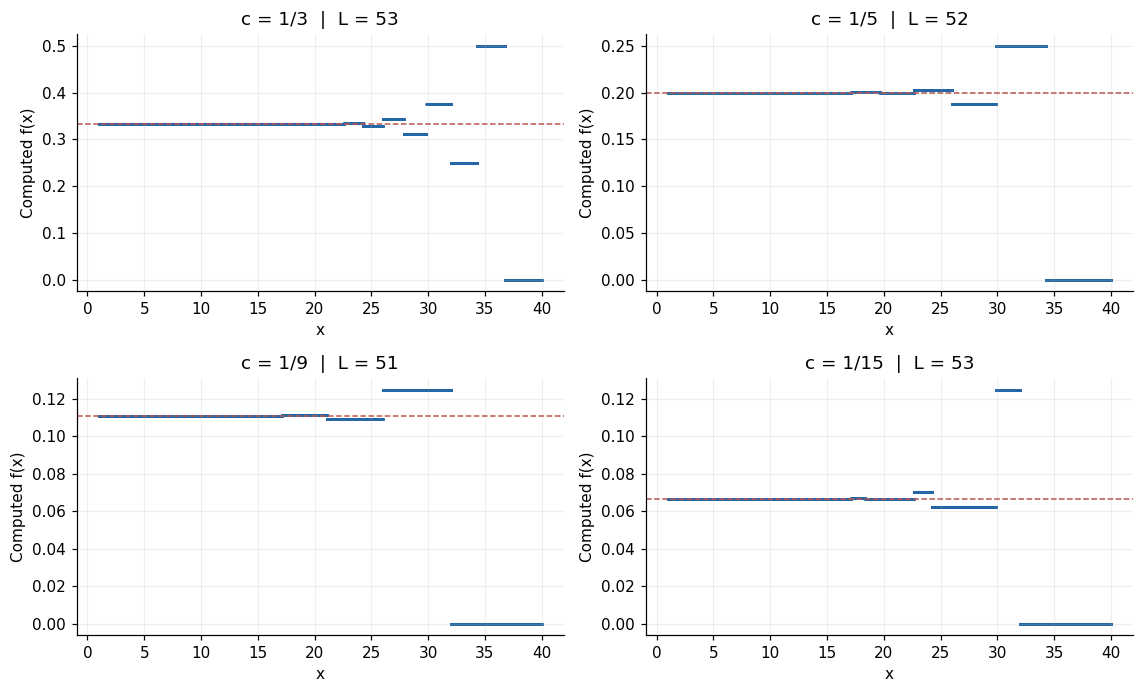

In [5]:
fig,axs=plt.subplots(2,2,figsize=(10.5,6.4))
for ax,d in zip(axs.ravel(),[3,5,9,15]):
    c=1/d;x=np.linspace(1,40,16000)
    f,_=evaluate(x,c)
    ax.scatter(x,f,color=BLUE,s=.55,rasterized=True)
    ax.axhline(c,color=RED,ls='--',lw=1)
    ax.set(xlabel='x',ylabel='Computed f(x)',title=f'c = 1/{d}  |  L = {theory(c).L}')
fig.tight_layout()
fig.savefig(FIG / '09_reciprocal_odd_fractions.png', bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)

## Conclusion

The onset and length of the noisy region depend on the **lowest stored set bit** $\nu(c)$, not just on the magnitude of $c$. For binary64 `0.1`, $x_1\approx0.871$ and $x_2=32$ ($L=52$); for `1/3`, the zone has $L=53$ binades. Very close to $x\approx1$ the condition $y\ge c$ and boundary assumptions should be checked before applying the idealized per-binade formula.